In [3]:
%pip install pandas numpy matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:
import pandas as pd
import numpy as np

data = {
    'Name': ['Rahul', 'Priya', 'Amit', 'Sneha', 'Rohan',
             'Neha', 'Karan', 'Pooja', 'Vikas', 'Anjali',
             'Rahul', 'Meera', 'Arjun', 'Simran', 'Dev',
             'Isha', 'Kabir', 'Riya', 'Varun', 'Tina'],

    'Age': [25, 28, 32, np.nan, 24, 29, 35, 27, 30, 26,
            25, 31,  np.nan, 28, 33, 24, 36, 29, 27, 30],

    'Salary': [30000, 45000, 55000, 40000, np.nan,
               60000, 75000, 35000, 50000, 42000,
               30000, 65000, 80000, 48000, 90000,
               32000, 70000, 52000, 45000, 110000],

    'Department': ['IT', 'HR', 'Finance', 'IT', 'HR',
                   'Sales', 'IT', 'Finance', 'Sales', 'HR',
                   'IT', 'Finance', 'IT', 'Sales', 'HR',
                   'IT', 'Finance', 'Sales', 'HR', 'IT'],

    'Gender': ['Male', 'Female', 'Male', 'Female', 'Male',
               'Female', 'Male', 'Female', 'Male', 'Female',
               'Male', 'Female', 'Male', 'Female', 'Male',
               'Female', 'Male', 'Female', 'Male', 'Female'],

    'Join_Date': ['2022-01-10', '2021-03-15', '2020-06-20',
                  '2023-02-12', '2022-08-05', '2021-11-18',
                  '2020-04-10', '2023-07-22', '2022-09-14',
                  '2021-05-19', '2022-01-10', '2020-12-01',
                  '2021-08-16', '2023-04-25', '2020-02-11',
                  '2022-10-30', '2019-07-15', '2021-06-09',
                  '2023-01-17', '2020-09-21']
}

df = pd.DataFrame(data)

# Add extra spaces to test text cleaning
df.loc[1, 'Name'] = ' Priya '

# Add an extreme salary value to test outlier handling
df.loc[5, 'Salary'] = 500000

# Save raw dataset
df.to_csv('employee_raw.csv', index=False)

print("Raw dataset created successfully!")
print(df)


Raw dataset created successfully!
       Name   Age    Salary Department  Gender   Join_Date
0     Rahul  25.0   30000.0         IT    Male  2022-01-10
1    Priya   28.0   45000.0         HR  Female  2021-03-15
2      Amit  32.0   55000.0    Finance    Male  2020-06-20
3     Sneha   NaN   40000.0         IT  Female  2023-02-12
4     Rohan  24.0       NaN         HR    Male  2022-08-05
5      Neha  29.0  500000.0      Sales  Female  2021-11-18
6     Karan  35.0   75000.0         IT    Male  2020-04-10
7     Pooja  27.0   35000.0    Finance  Female  2023-07-22
8     Vikas  30.0   50000.0      Sales    Male  2022-09-14
9    Anjali  26.0   42000.0         HR  Female  2021-05-19
10    Rahul  25.0   30000.0         IT    Male  2022-01-10
11    Meera  31.0   65000.0    Finance  Female  2020-12-01
12    Arjun   NaN   80000.0         IT    Male  2021-08-16
13   Simran  28.0   48000.0      Sales  Female  2023-04-25
14      Dev  33.0   90000.0         HR    Male  2020-02-11
15     Isha  24.0   32

In [6]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Missing Values:
Name          0
Age           2
Salary        1
Department    0
Gender        0
Join_Date     0
dtype: int64

Total Missing Values:
3


In [20]:
# Fill Age missing values with median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill Salary missing values with mean
df['Salary'] = df['Salary'].fillna(df['Salary'].median())

# Check again
print(df.isnull().sum())

Name          0
Age           0
Salary        0
Department    0
Gender        0
Join_Date     0
dtype: int64


In [8]:
# Remove extra spaces
df['Name'] = df['Name'].str.strip()

# Convert text into lowercase
df['Name'] = df['Name'].str.lower()

# Remove duplicate records based on Name
df = df.drop_duplicates(subset='Name', keep='first')

# Display result
print("Dataset after text cleaning and duplicate removal:")
print(df)

print("\nTotal rows:", len(df))


Dataset after text cleaning and duplicate removal:
      Name   Age         Salary Department  Gender   Join_Date
0    rahul  25.0   30000.000000         IT    Male  2022-01-10
1    priya  28.0   45000.000000         HR  Female  2021-03-15
2     amit  32.0   55000.000000    Finance    Male  2020-06-20
3    sneha  28.5   40000.000000         IT  Female  2023-02-12
4    rohan  24.0   78631.578947         HR    Male  2022-08-05
5     neha  29.0  500000.000000      Sales  Female  2021-11-18
6    karan  35.0   75000.000000         IT    Male  2020-04-10
7    pooja  27.0   35000.000000    Finance  Female  2023-07-22
8    vikas  30.0   50000.000000      Sales    Male  2022-09-14
9   anjali  26.0   42000.000000         HR  Female  2021-05-19
11   meera  31.0   65000.000000    Finance  Female  2020-12-01
12   arjun  28.5   80000.000000         IT    Male  2021-08-16
13  simran  28.0   48000.000000      Sales  Female  2023-04-25
14     dev  33.0   90000.000000         HR    Male  2020-02-11
15  

In [9]:
# Calculate Q1 and Q3
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

# Remove outliers
df = df[(df['Salary'] >= lower_limit) &
        (df['Salary'] <= upper_limit)]

print("\nDataset after outlier removal:")
print(df)
print("\nTotal rows:", len(df))


Lower Limit: -6473.68421052632
Upper Limit: 126789.47368421053

Dataset after outlier removal:
      Name   Age         Salary Department  Gender   Join_Date
0    rahul  25.0   30000.000000         IT    Male  2022-01-10
1    priya  28.0   45000.000000         HR  Female  2021-03-15
2     amit  32.0   55000.000000    Finance    Male  2020-06-20
3    sneha  28.5   40000.000000         IT  Female  2023-02-12
4    rohan  24.0   78631.578947         HR    Male  2022-08-05
6    karan  35.0   75000.000000         IT    Male  2020-04-10
7    pooja  27.0   35000.000000    Finance  Female  2023-07-22
8    vikas  30.0   50000.000000      Sales    Male  2022-09-14
9   anjali  26.0   42000.000000         HR  Female  2021-05-19
11   meera  31.0   65000.000000    Finance  Female  2020-12-01
12   arjun  28.5   80000.000000         IT    Male  2021-08-16
13  simran  28.0   48000.000000      Sales  Female  2023-04-25
14     dev  33.0   90000.000000         HR    Male  2020-02-11
15    isha  24.0   3200

In [10]:
df['Join_Date'] = pd.to_datetime(df['Join_Date'])

print(df.dtypes)


Name                     str
Age                  float64
Salary               float64
Department               str
Gender                   str
Join_Date     datetime64[us]
dtype: object


In [11]:
df_encoded = pd.get_dummies(
    df,
    columns=['Department', 'Gender'],
    dtype=int
)

print(df_encoded.head())

    Name   Age        Salary  Join_Date  Department_Finance  Department_HR  \
0  rahul  25.0  30000.000000 2022-01-10                   0              0   
1  priya  28.0  45000.000000 2021-03-15                   0              1   
2   amit  32.0  55000.000000 2020-06-20                   1              0   
3  sneha  28.5  40000.000000 2023-02-12                   0              0   
4  rohan  24.0  78631.578947 2022-08-05                   0              1   

   Department_IT  Department_Sales  Gender_Female  Gender_Male  
0              1                 0              0            1  
1              0                 0              1            0  
2              0                 0              0            1  
3              1                 0              1            0  
4              0                 0              0            1  


In [12]:
df.to_csv('employee_cleaned.csv', index=False)

df_encoded.to_csv('employee_encoded.csv', index=False)

print("Both CSV files saved successfully!")


Both CSV files saved successfully!


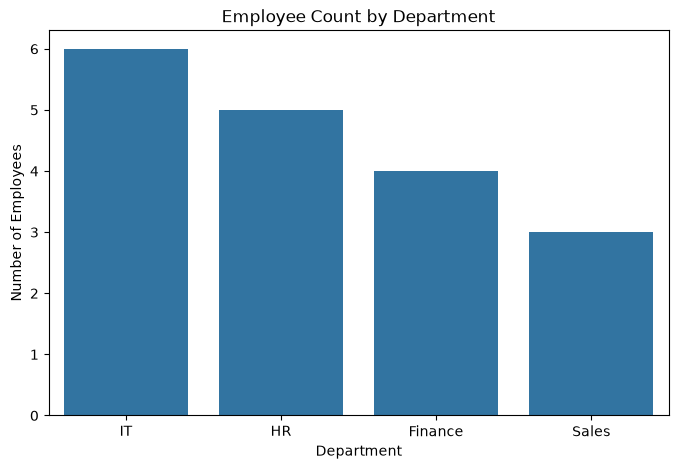

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Department')

plt.title('Employee Count by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')

plt.show()


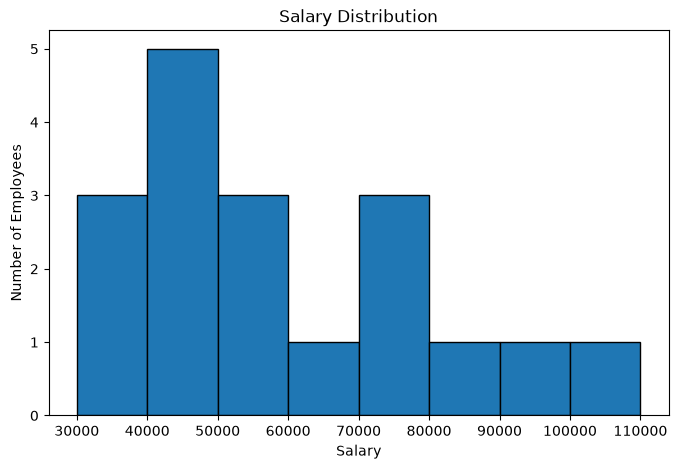

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(df['Salary'], bins=8, edgecolor='black')

plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Number of Employees')

plt.show()


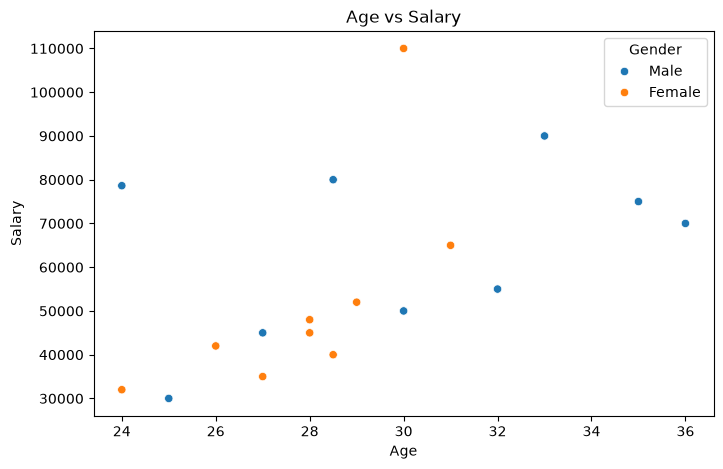

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='Age', y='Salary', hue='Gender')

plt.title('Age vs Salary')
plt.xlabel('Age')
plt.ylabel('Salary')

plt.show()


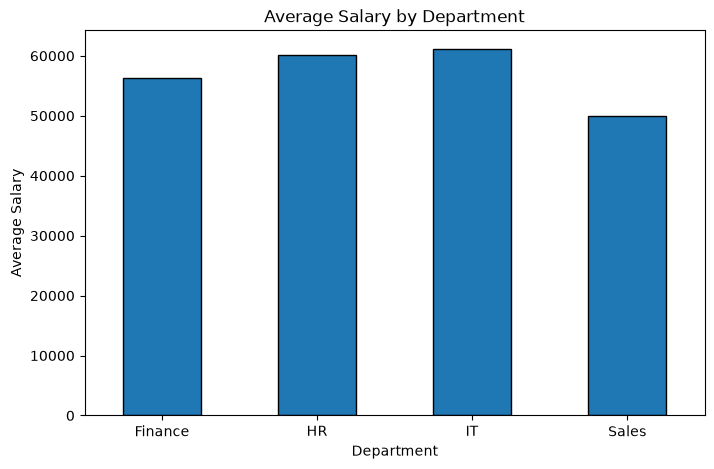

In [16]:
avg_salary = df.groupby('Department')['Salary'].mean()

plt.figure(figsize=(8, 5))

avg_salary.plot(kind='bar', edgecolor='black')

plt.title('Average Salary by Department')
plt.xlabel('Department')
plt.ylabel('Average Salary')

plt.xticks(rotation=0)
plt.show()


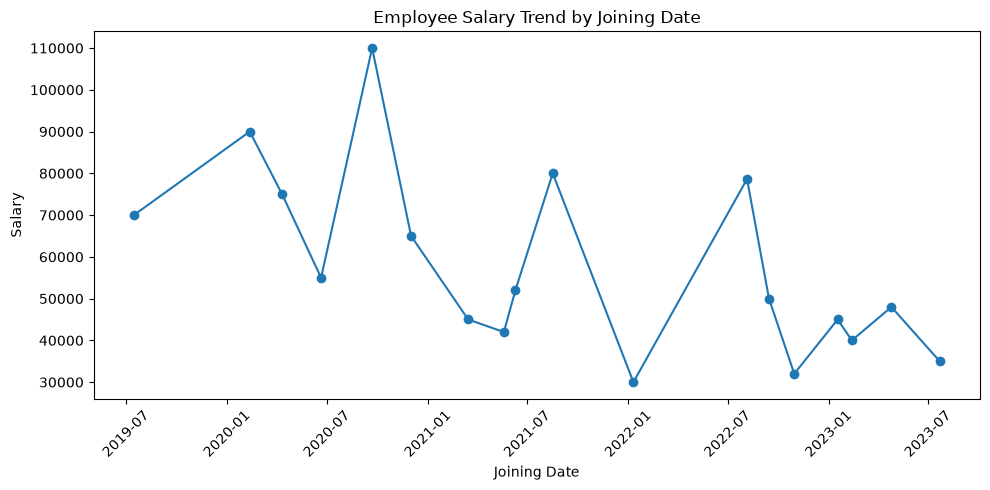

In [17]:
date_salary = df.sort_values('Join_Date')

plt.figure(figsize=(10, 5))

plt.plot(date_salary['Join_Date'], date_salary['Salary'], marker='o')

plt.title('Employee Salary Trend by Joining Date')
plt.xlabel('Joining Date')
plt.ylabel('Salary')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


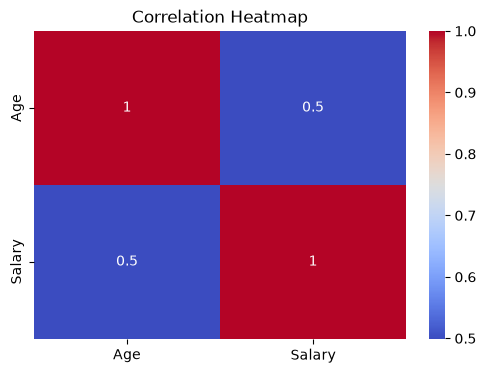

In [18]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    df[['Age', 'Salary']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()


In [19]:
print("Total Employees:", len(df))
print("\nAverage Age:", round(df['Age'].mean(), 2))
print("Average Salary:", round(df['Salary'].mean(), 2))
print("Highest Salary:", df['Salary'].max())
print("Lowest Salary:", df['Salary'].min())

print("\nDepartment-wise Employee Count:")
print(df['Department'].value_counts())

print("\nDepartment-wise Average Salary:")
print(df.groupby('Department')['Salary'].mean().round(2))


Total Employees: 18

Average Age: 29.0
Average Salary: 57923.98
Highest Salary: 110000.0
Lowest Salary: 30000.0

Department-wise Employee Count:
Department
IT         6
HR         5
Finance    4
Sales      3
Name: count, dtype: int64

Department-wise Average Salary:
Department
Finance    56250.00
HR         60126.32
IT         61166.67
Sales      50000.00
Name: Salary, dtype: float64


In [21]:
from pathlib import Path

project = Path("Thiranex_Task_1")

(project / "Dataset").mkdir(parents=True, exist_ok=True)
(project / "Visualizations").mkdir(parents=True, exist_ok=True)
(project / "Report").mkdir(parents=True, exist_ok=True)

df.to_csv(project / "Dataset" / "employee_cleaned.csv", index=False)
df_encoded.to_csv(project / "Dataset" / "employee_encoded.csv", index=False)

print("Project folders and datasets created successfully!")


Project folders and datasets created successfully!


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Department Employee Count
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Department')
plt.title('Employee Count by Department')
plt.savefig(project / "Visualizations" / "department_count.png", bbox_inches='tight')
plt.close()

# 2. Salary Distribution
plt.figure(figsize=(8, 5))
plt.hist(df['Salary'], bins=8, edgecolor='black')
plt.title('Salary Distribution')
plt.savefig(project / "Visualizations" / "salary_distribution.png", bbox_inches='tight')
plt.close()

# 3. Age vs Salary
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Age', y='Salary', hue='Gender')
plt.title('Age vs Salary')
plt.savefig(project / "Visualizations" / "age_vs_salary.png", bbox_inches='tight')
plt.close()

# 4. Average Salary by Department
plt.figure(figsize=(8, 5))
df.groupby('Department')['Salary'].mean().plot(kind='bar')
plt.title('Average Salary by Department')
plt.savefig(project / "Visualizations" / "average_salary.png", bbox_inches='tight')
plt.close()

# 5. Salary Trend by Joining Date
date_salary = df.sort_values('Join_Date')
plt.figure(figsize=(10, 5))
plt.plot(date_salary['Join_Date'], date_salary['Salary'], marker='o')
plt.title('Salary Trend by Joining Date')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(project / "Visualizations" / "salary_trend.png", bbox_inches='tight')
plt.close()

# 6. Correlation Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(df[['Age', 'Salary']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.savefig(project / "Visualizations" / "correlation_heatmap.png", bbox_inches='tight')
plt.close()

print("All 6 visualizations saved successfully!")


All 6 visualizations saved successfully!


In [23]:
from pathlib import Path

print("Raw Dataset:", Path("employee_raw.csv").exists())
print("Cleaned Dataset:", (project / "Dataset" / "employee_cleaned.csv").exists())
print("Encoded Dataset:", (project / "Dataset" / "employee_encoded.csv").exists())
print("Visualization Files:", len(list((project / "Visualizations").glob("*.png"))))


Raw Dataset: True
Cleaned Dataset: True
Encoded Dataset: True
Visualization Files: 6


In [24]:
%pip install reportlab


   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   -------------------- ------------------- 1.0/2.0 MB 6.0 MB/s eta 0:00:01
   ------------------------------------ --- 1.8/2.0 MB 4.7 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 4.1 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image, PageBreak
)
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib import colors
from reportlab.lib.units import inch

pdf_path = project / "Report" / "Task_1_Final_Report.pdf"

doc = SimpleDocTemplate(
    str(pdf_path),
    pagesize=(8.27*inch, 11.69*inch)
)

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    'MainTitle',
    parent=styles['Title'],
    alignment=TA_CENTER,
    textColor=colors.darkblue,
    spaceAfter=20
)

story = []

story.append(Paragraph(
    "DATA CLEANING AND VISUALIZATION PROJECT",
    title_style
))

story.append(Paragraph("Thiranex EduTech LLP - Internship Task 1", styles['Heading2']))
story.append(Spacer(1, 15))

sections = [
    ("1. Introduction",
     "This project demonstrates data cleaning and exploratory data analysis using Python. A synthetic employee dataset was created for this internship task."),

    ("2. Objective",
     "To identify and handle missing values, duplicate records and outliers, and understand employee data through statistical analysis and visualizations."),

    ("3. Tools and Technologies",
     "Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook and ReportLab."),

    ("4. Dataset Description",
     "The synthetic dataset initially contained 20 employee records and six columns: Name, Age, Salary, Department, Gender and Join_Date."),

    ("5. Data Cleaning",
     "Missing Age values were filled using the median. The missing Salary value was filled using the median. Text values were standardized, duplicate names were removed, and salary outliers were handled using the IQR method. Join_Date was converted into datetime format. Department and Gender were encoded using One-Hot Encoding."),

    ("6. Statistical Findings",
     "Total employees after cleaning: 18<br/>"
     "Average age: 29 years<br/>"
     "Average salary: Rs. 57,923.98<br/>"
     "Highest salary: Rs. 1,10,000<br/>"
     "Lowest salary: Rs. 30,000<br/>"
     "Department employee counts: IT - 6, HR - 5, Finance - 4, Sales - 3."),

    ("7. Key Insights",
     "IT had the highest employee count and highest average salary (Rs. 61,166.67). Sales had the lowest average salary (Rs. 50,000). The analysis also explored salary distribution and the relationship between age and salary."),

    ("8. Conclusion",
     "The project successfully demonstrated data cleaning, preprocessing and exploratory data analysis using Python. Visualizations and statistical summaries helped identify patterns in the synthetic employee dataset.")
]

for heading, content in sections:
    story.append(Paragraph(heading, styles['Heading2']))
    story.append(Paragraph(content, styles['BodyText']))
    story.append(Spacer(1, 12))

story.append(PageBreak())
story.append(Paragraph("9. Data Visualizations", styles['Heading1']))

graph_files = [
    ("Employee Count by Department", "department_count.png"),
    ("Salary Distribution", "salary_distribution.png"),
    ("Age vs Salary", "age_vs_salary.png"),
    ("Average Salary by Department", "average_salary.png"),
    ("Salary Trend by Joining Date", "salary_trend.png"),
    ("Correlation Heatmap", "correlation_heatmap.png")
]

for heading, filename in graph_files:
    story.append(Paragraph(heading, styles['Heading2']))
    img_path = project / "Visualizations" / filename
    story.append(Image(str(img_path), width=6*inch, height=3.3*inch))
    story.append(Spacer(1, 15))

doc.build(story)

print("Final Report PDF created successfully!")
print("Location:", pdf_path)


Final Report PDF created successfully!
Location: Thiranex_Task_1\Report\Task_1_Final_Report.pdf


In [26]:
print("PDF exists:", pdf_path.exists())
print("Report folder contents:", list((project / "Report").iterdir()))


PDF exists: True
Report folder contents: [WindowsPath('Thiranex_Task_1/Report/Task_1_Final_Report.pdf')]


In [27]:
import os
os.startfile(pdf_path.resolve())


In [28]:
import os

print("Current folder:", os.getcwd())
print("\nNotebook files:")

for file in os.listdir():
    if file.endswith(".ipynb"):
        print(file)
        

Current folder: C:\Users\Rupesh.Amin

Notebook files:
Data_Cleaning_EDA.ipynb
